# Trabajo Práctico Especial

## Fundamentos de la Ciencia de Datos 2026

### Análisis del conjunto de datos CKD-NHANES 2021-2023


Nuestro trabajo tiene como objetivo realizar un análisis exploratorio y estadístico del conjunto de datos CKD-NHAMES 2021-2023, relacionado con la enfermedad renal crónica (CKD).

El dataset contiene información de personas examinadas en Estados Unidos durante el periodo 2021-2023, incluyendo caracteristicas demográficas, medidas corporales, presión arterial, análisis de sangre y orina, antecedentes de diabetes y tabaquismo, y otras variables relacionadas con la función renal.

A partir de estos datos realizaremos una exploración inicial del conjunto, donde analizaremos la necesidad de realizar tareas de limpieza y se plantearán y validarán distintas hipótesis relacionadas con la enfermedad renal crónica.

#### Un poco de contexto y variables de interés
La enfermedad renal crónica es una condición relacionada con alteraciones persistentes en el funcionamiento de los riñones.

Para evaluar la función renal se utilizaran principalmente dos indicadores:
- **eGFR:** estima la velocidad de filtración glomerular y permite evaluar qué tan bien están filtrando los riñones.
- **ACR** representa la relación albúmina/creatinina en orina y permite detectar la presencia de almbúmina en la orina.

En el conjunto de datos también se encuentra la variable **ckd_stage**, que representa el estadio de la enfermedad renal crónica, y **ckd_present**, que indica mediante una variable binaria si se presenta CKD según la clasificación utilizada en el conjunto.

Por este motivo, no vamos a asumir que todo **ckd_present = 1** es un caso confirmado de CKD, lo vamos a analizar cuidadosamente.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### Cargamos el Data Set y comenzamos a ver su información:

In [2]:
df = pd.read_csv("CKD_NHANES_2021_2023.csv")

In [3]:
df.head()

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,...,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,...,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,...,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,...,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,...,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1


In [4]:
df.shape

(11933, 29)

In [5]:
df.columns

Index(['participant_id', 'age', 'gender', 'ethnicity', 'education_level',
       'poverty_income_ratio', 'bmi', 'weight_kg', 'height_cm', 'bp_systolic',
       'bp_diastolic', 'serum_creatinine', 'blood_urea_nitrogen',
       'albumin_serum', 'phosphorus', 'bicarbonate', 'calcium', 'uric_acid',
       'urine_creatinine', 'urine_albumin', 'albumin_creatinine_ratio',
       'diabetes_diagnosed', 'insulin_use', 'diabetes_pills', 'ever_smoked',
       'current_smoker', 'egfr', 'ckd_stage', 'ckd_present'],
      dtype='str')

##### Exploración inicial del conjunto de datos
A partir de aca realizaremos una exploración inicial del conjunto de datos con el objetivo de conocer su estructura, tipos de variables, valores presentes, datos faltantes y posibles caracteristicas relevantes para el análisis posterior.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   participant_id            11933 non-null  float64
 1   age                       11933 non-null  float64
 2   gender                    11933 non-null  str    
 3   ethnicity                 11933 non-null  str    
 4   education_level           7794 non-null   float64
 5   poverty_income_ratio      9892 non-null   float64
 6   bmi                       8471 non-null   float64
 7   weight_kg                 8754 non-null   float64
 8   height_cm                 8499 non-null   float64
 9   bp_systolic               7517 non-null   float64
 10  bp_diastolic              7517 non-null   float64
 11  serum_creatinine          6326 non-null   float64
 12  blood_urea_nitrogen       6326 non-null   float64
 13  albumin_serum             6366 non-null   float64
 14  phosphorus       

### Variables disponibles
Aclaración: tenemos en cuenta que no todas las variables numéricas son necesariamente cuantitativas, ya que algunas representan categorias, por lo que no las vamos a tratar como variables continuas.

In [7]:
df.dtypes

participant_id              float64
age                         float64
gender                          str
ethnicity                       str
education_level             float64
poverty_income_ratio        float64
bmi                         float64
weight_kg                   float64
height_cm                   float64
bp_systolic                 float64
bp_diastolic                float64
serum_creatinine            float64
blood_urea_nitrogen         float64
albumin_serum               float64
phosphorus                  float64
bicarbonate                 float64
calcium                     float64
uric_acid                   float64
urine_creatinine            float64
urine_albumin               float64
albumin_creatinine_ratio    float64
diabetes_diagnosed          float64
insulin_use                 float64
diabetes_pills              float64
ever_smoked                 float64
current_smoker              float64
egfr                        float64
ckd_stage                   

#### Clasificación:
##### Cualitativas/categóricas:
Nominales:
- gender
- ethnicity
- insulin_use
- diabetes_pills
- ever_smoked
- ckd_present
- current_smoker (Su núm no representa necesariamente una escala ordinal)
- diabetes_diagnosed

Ordinales:
- education_level
- ckd_stage

##### Cuantitativas:
Continuas:
- poverty_income_Ratio
- bmi
- weight_cm
- height_cm
- bp_systolic
- bp_diastolic
- serum_creatinine
- blood_urea_nitrogen
- albumin_serum
- phosphorus
- bicarbonate
- calcium
- uric_acid
- urine_creatinine
- urine_albumin
- albumin_creatinine_ratio
- egfr

Discretas:
- age

##### Identificador:
- participant_id

In [8]:
df.describe()

,participant_id,age,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,...,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_present
count,11933.000000,1.193300e+04,7794.000000,9.892000e+03,8471.000000,8754.000000,8499.000000,7517.000000,7517.000000,6326.000000,...,8154.000000,8153.000000,8153.000000,11740.000000,1081.000000,2281.000000,8135.000000,3243.000000,6326.000000,11933.000000
mean,136344.000000,3.831786e+01,3.804978,2.708174e+00,27.246665,70.549037,159.664549,119.288546,72.748038,0.872828,...,133.258646,35.567928,33.355533,1.934497,1.681776,1.633494,1.611678,2.339500,96.599750,0.698986
std,3444.904716,2.560199e+01,1.153750,1.670119e+00,8.137781,30.389021,19.864943,18.561052,11.895572,0.385498,...,90.676053,175.582217,251.094041,0.358726,0.466002,0.635776,0.558182,0.900889,24.633731,0.458718
min,130378.000000,5.397605e-79,1.000000,5.397605e-79,11.100000,2.700000,79.100000,61.000000,33.000000,0.330000,...,4.000000,0.210000,0.080000,1.000000,1.000000,1.000000,1.000000,1.000000,3.510000,0.000000
25%,133361.000000,1.300000e+01,3.000000,1.180000e+00,21.600000,54.200000,154.400000,106.000000,64.000000,0.700000,...,65.000000,5.770000,5.420000,2.000000,1.000000,1.000000,1.000000,1.000000,80.502500,0.000000
50%,136344.000000,3.700000e+01,4.000000,2.500000e+00,26.400000,71.700000,163.600000,117.000000,72.000000,0.830000,...,117.000000,9.620000,8.270000,2.000000,2.000000,2.000000,2.000000,3.000000,97.030000,1.000000
75%,139327.000000,6.200000e+01,5.000000,4.500000e+00,31.700000,89.100000,172.100000,130.000000,80.000000,0.980000,...,181.000000,17.830000,15.330000,2.000000,2.000000,2.000000,2.000000,3.000000,112.660000,1.000000
max,142310.000000,8.000000e+01,9.000000,5.000000e+00,74.800000,248.200000,200.700000,232.000000,142.000000,15.170000,...,873.000000,7942.470000,14708.280000,9.000000,2.000000,9.000000,9.000000,3.000000,178.430000,1.000000


A continuación mostraremos cuantos valores faltantes tiene cada variable del conjunto de datos para su posterior limpieza según corresponda.

In [9]:
df.isnull().sum()

participant_id                  0
age                             0
gender                          0
ethnicity                       0
education_level              4139
poverty_income_ratio         2041
bmi                          3462
weight_kg                    3179
height_cm                    3434
bp_systolic                  4416
bp_diastolic                 4416
serum_creatinine             5607
blood_urea_nitrogen          5607
albumin_serum                5567
phosphorus                   5611
bicarbonate                  5608
calcium                      5571
uric_acid                    5604
urine_creatinine             3779
urine_albumin                3780
albumin_creatinine_ratio     3780
diabetes_diagnosed            193
insulin_use                 10852
diabetes_pills               9652
ever_smoked                  3798
current_smoker               8690
egfr                         5607
ckd_stage                       0
ckd_present                     0
dtype: int64

Ya sabemos que por la exploración del dataset que **serum_creatinine** y **egfr** tienen muchos faltantes, y eso está relacionado con la población por la cual se realizó esa medición. Además la guia nos aclara que algunas variables como **insulin_use** y **diabetes_pills**, corresponden solamente a determinados subconjuntos de personas.

### Análisis de variables categóricas


In [10]:
print("Gender:")
print(df["gender"].value_counts(dropna=False))

print("\nEthnicity:")
print(df["ethnicity"].value_counts(dropna=False))

print("\nCKD Stage:")
print(df["ckd_stage"].value_counts(dropna=False))

print("\nCKD Present:")
print(df["ckd_present"].value_counts(dropna=False))

Gender:
gender
Female    6358
Male      5575
Name: count, dtype: int64

Ethnicity:
ethnicity
Non-Hispanic White    6217
Non-Hispanic Black    1597
Other Hispanic        1373
Mexican American      1117
Other/Multiracial      948
Non-Hispanic Asian     681
Name: count, dtype: int64

CKD Stage:
ckd_stage
Unknown                         5607
No CKD                          3592
Stage 2 (Mildly Decreased)      1875
Stage 1 (Kidney Damage)          382
Stage 3a (Mild-Moderate)         341
Stage 3b (Moderate-Severe)        97
Stage 4 (Severely Decreased)      28
Stage 5 (Kidney Failure)          11
Name: count, dtype: int64

CKD Present:
ckd_present
1    8341
0    3592
Name: count, dtype: int64


#### Distribución de la enfermedad renal crónica

In [11]:
df["ckd_stage"].value_counts()

ckd_stage
Unknown                         5607
No CKD                          3592
Stage 2 (Mildly Decreased)      1875
Stage 1 (Kidney Damage)          382
Stage 3a (Mild-Moderate)         341
Stage 3b (Moderate-Severe)        97
Stage 4 (Severely Decreased)      28
Stage 5 (Kidney Failure)          11
Name: count, dtype: int64

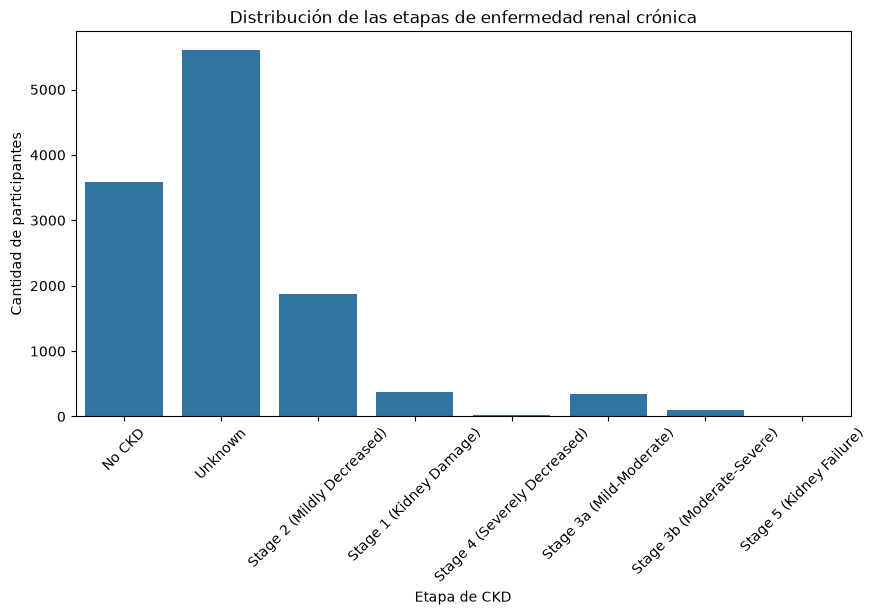

In [12]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="ckd_stage")

plt.title("Distribución de las etapas de enfermedad renal crónica")
plt.xlabel("Etapa de CKD")
plt.ylabel("Cantidad de participantes")
plt.xticks(rotation=45)

plt.show()

Histogramas relevantes:

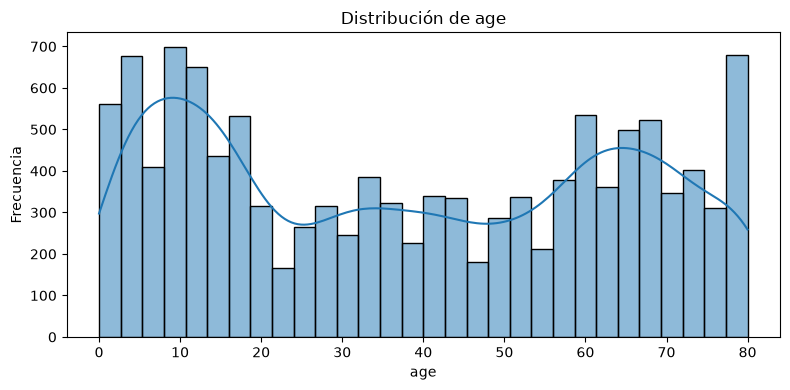

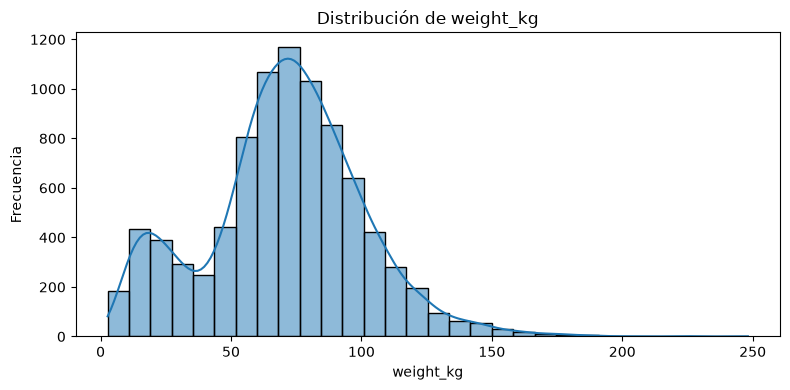

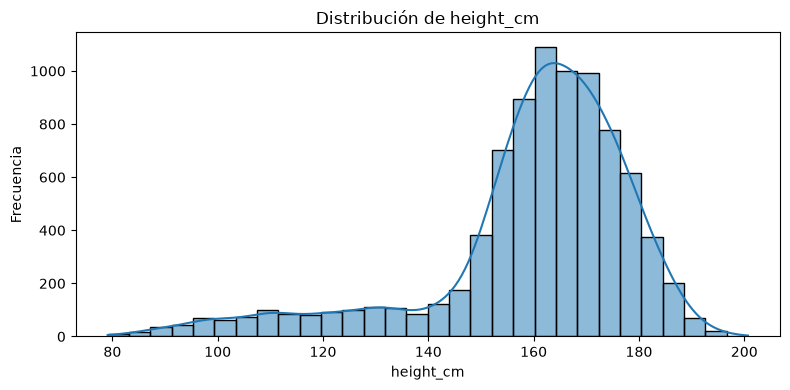

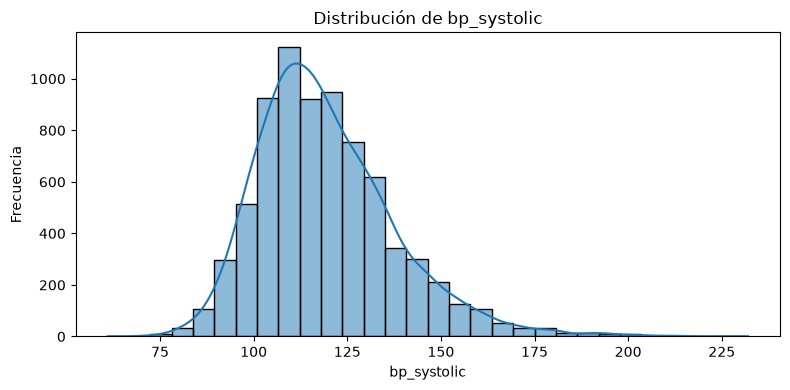

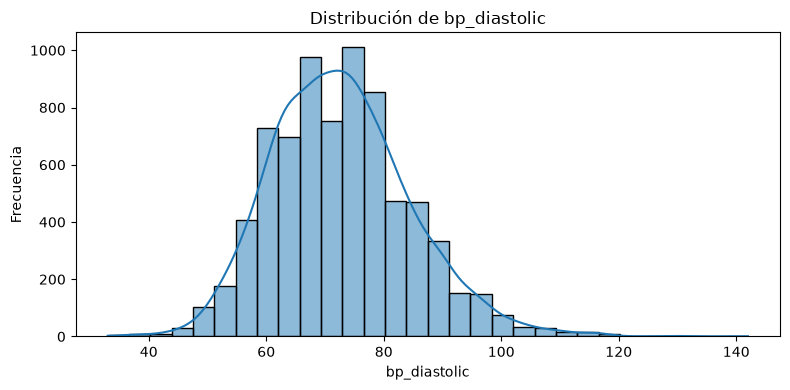

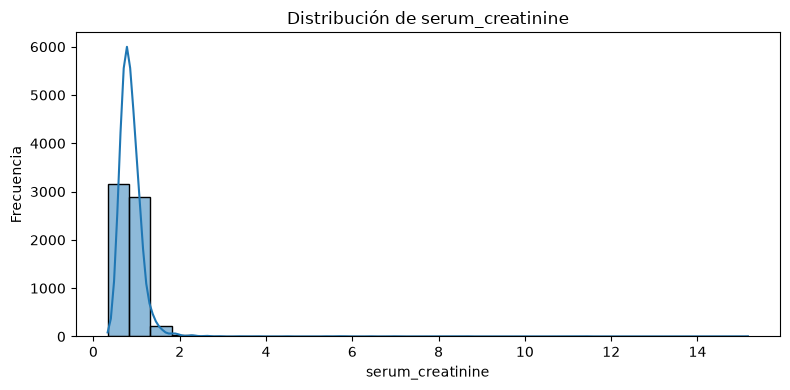

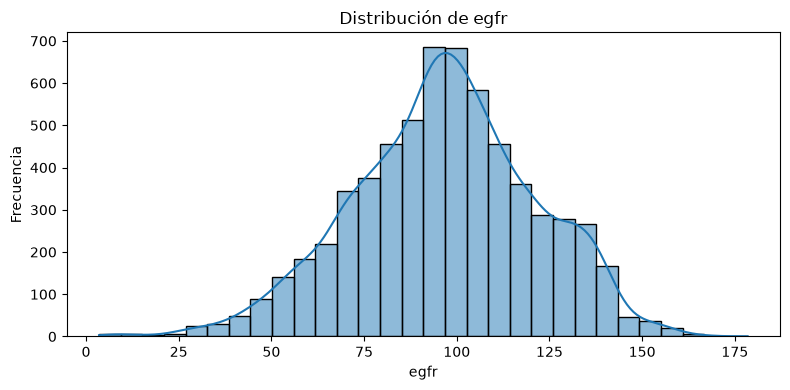

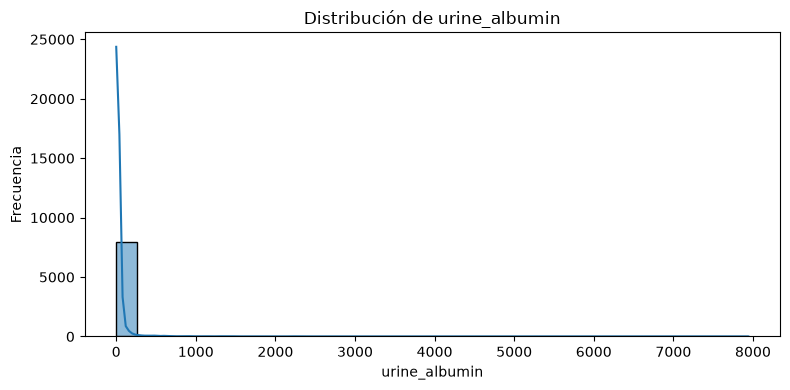

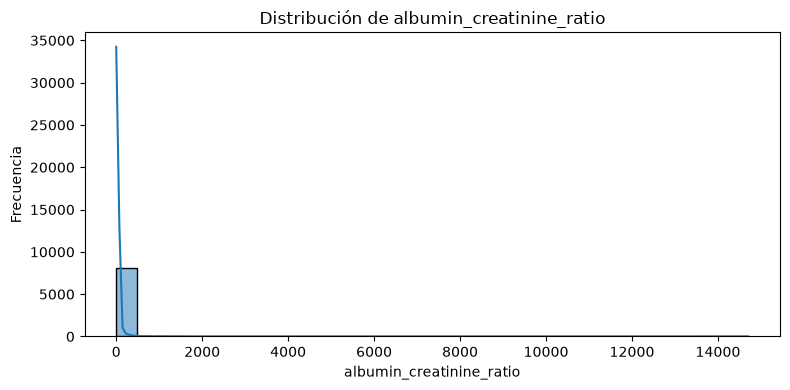

In [13]:

variables_histogramas = [
    "age",
    "weight_kg",
    "height_cm",
    "bp_systolic",
    "bp_diastolic",
    "serum_creatinine",
    "egfr",
    "urine_albumin",
    "albumin_creatinine_ratio"
]

for variable in variables_histogramas:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=variable, bins=30, kde=True)
    plt.title(f"Distribución de {variable}")
    plt.xlabel(variable)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()


Calculamos cuantos valores faltan en cada columna y qué porcentaje representan sobre las 11933 filas:

In [14]:

faltantes = pd.DataFrame({
    "Cantidad_faltante": df.isnull().sum(),
    "Porcentaje_faltante": (df.isnull().mean() * 100).round(2)
})

faltantes = faltantes.sort_values(
    by="Porcentaje_faltante",
    ascending=False
)

display(faltantes)


,Cantidad_faltante,Porcentaje_faltante
insulin_use,10852,90.94
diabetes_pills,9652,80.88
current_smoker,8690,72.82
phosphorus,5611,47.02
bicarbonate,5608,47.00
blood_urea_nitrogen,5607,46.99
serum_creatinine,5607,46.99
egfr,5607,46.99
uric_acid,5604,46.96
calcium,5571,46.69


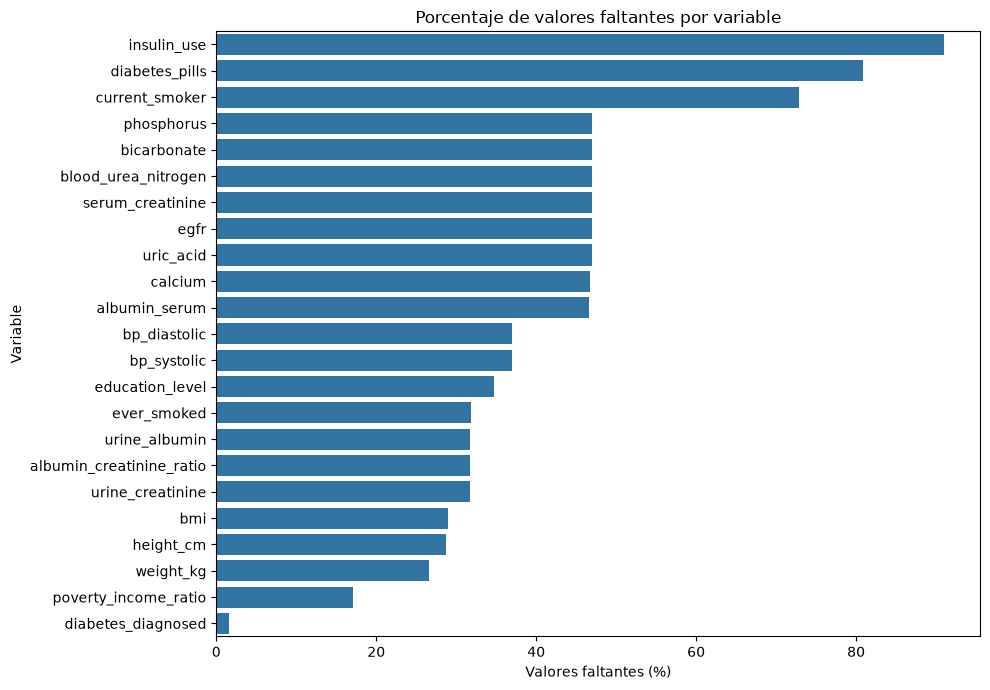

In [17]:

faltantes_con_datos = faltantes[
    faltantes["Cantidad_faltante"] > 0
]

plt.figure(figsize=(10, 7))
sns.barplot(
    data=faltantes_con_datos.reset_index(),
    x="Porcentaje_faltante",
    y="index"
)
plt.title("Porcentaje de valores faltantes por variable")
plt.xlabel("Valores faltantes (%)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


### Boxplotssss

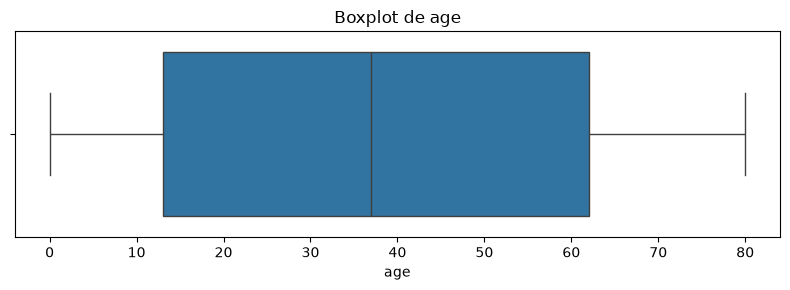

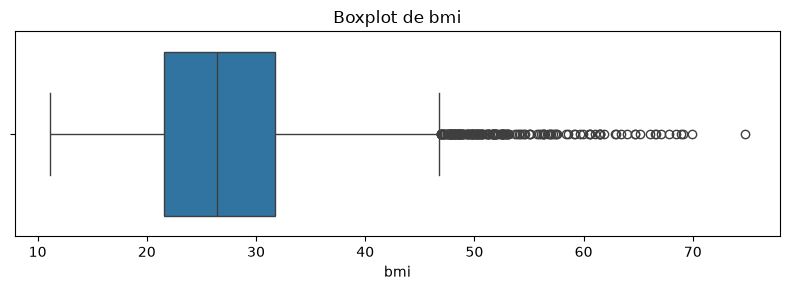

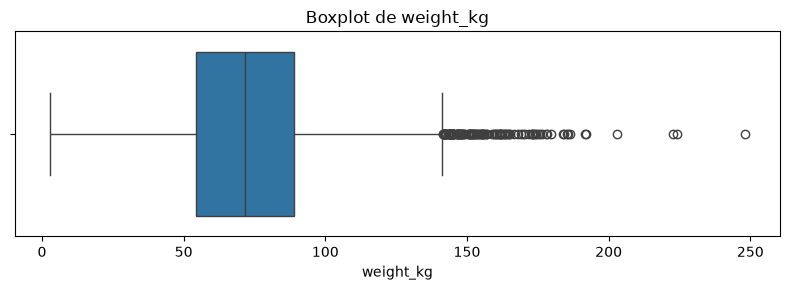

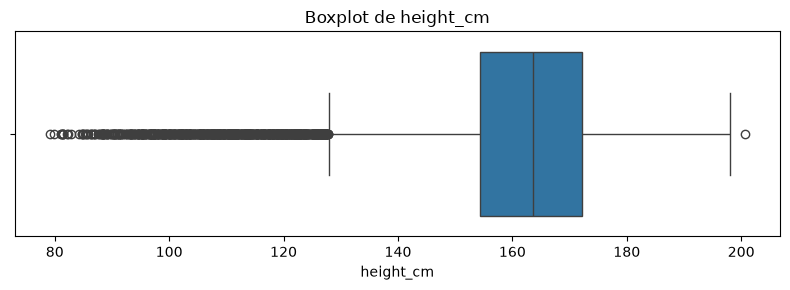

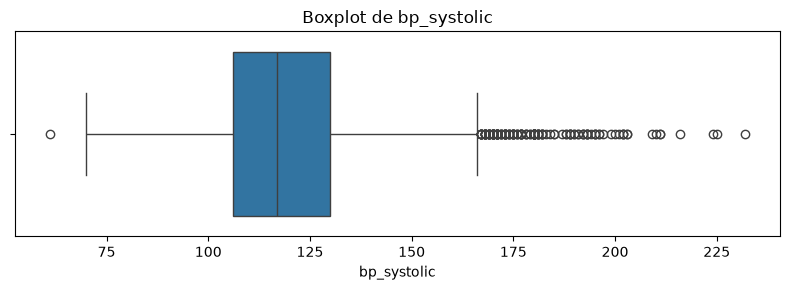

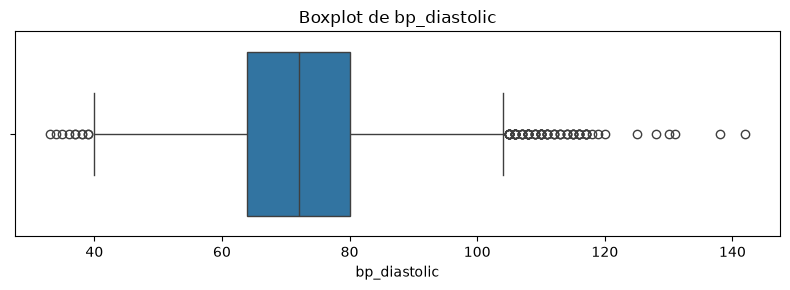

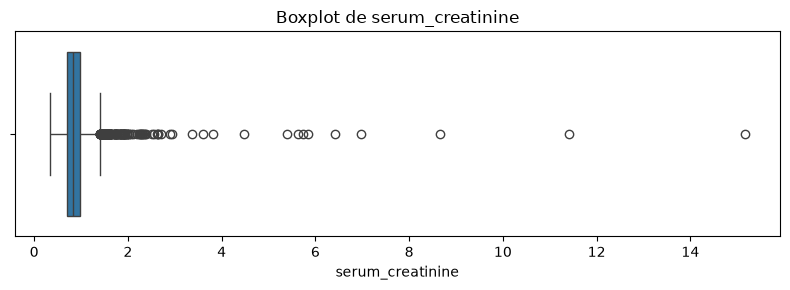

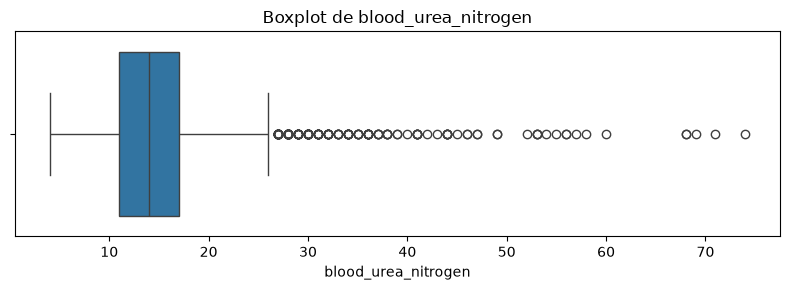

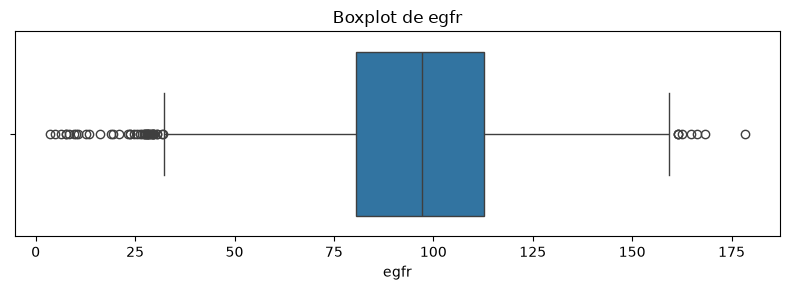

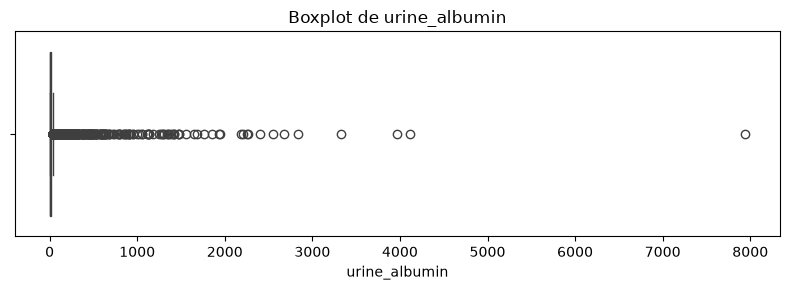

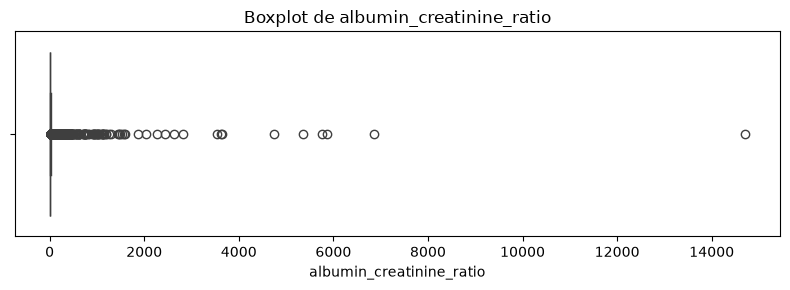

In [15]:

variables_boxplot = [
    "age",
    "bmi",
    "weight_kg",
    "height_cm",
    "bp_systolic",
    "bp_diastolic",
    "serum_creatinine",
    "blood_urea_nitrogen",
    "egfr",
    "urine_albumin",
    "albumin_creatinine_ratio"
]

for variable in variables_boxplot:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[variable])
    plt.title(f"Boxplot de {variable}")
    plt.xlabel(variable)
    plt.tight_layout()
    plt.show()


### Observaciones de los boxplots
##### para estudiar los posibles outliers
En la variable **edad** no observamos puntos aislados fuera de los bigotes. Aunque, tenemos en cuenta que los valores de edad iguales a 80 representan a personas de 80 años o más.

En el **bmi** y el **peso** identificamos numerosas obervaciones por encima del limite superior de los bigotes. Esto nos indica la presencia de valores elevados respecto de la distribución central.

En la variable **altura** observamos valores bajos alejados del resto de las obervaciones. Aunque para esto consideramos que el conjunto incluye participantes de distintas edades.

Las variables de **presión arterial sistólica** y **diastólica** presentan obversaciones alejadas de la distribución central, especialmente hacia los valores altos. (REVISAR)

Las variables de laboratorio **creatinina sérica** y **nitrógeno ureico en sangre** muestran distribuciones asimétricas hacia la derecha, con algunos valores elevados. También observamos valores bajos y altos alejados de la distribución central en el **egfr**.

Por último, la **albúmina en orina** y la relación **albúmina/creatinina** presentan una fuerte asimetría hacia la derecha, con obervaciones extremadamente elevadas en comparación con la mayor de los registros.

##### Calculamos cuantos posibles outliers hay en cada variable

In [16]:

for variable in variables_boxplot:
    datos = df[variable].dropna()

    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    atipicos = datos[
        (datos < limite_inferior) |
        (datos > limite_superior)
    ]

    porcentaje = len(atipicos) / len(datos) * 100

    print(
        f"{variable}: {len(atipicos)} posibles outliers "
        f"({porcentaje:.2f}%)"
    )


age: 0 posibles outliers (0.00%)
bmi: 189 posibles outliers (2.23%)
weight_kg: 137 posibles outliers (1.56%)
height_cm: 770 posibles outliers (9.06%)
bp_systolic: 143 posibles outliers (1.90%)
bp_diastolic: 93 posibles outliers (1.24%)
serum_creatinine: 183 posibles outliers (2.89%)
blood_urea_nitrogen: 194 posibles outliers (3.07%)
egfr: 51 posibles outliers (0.81%)
urine_albumin: 1004 posibles outliers (12.31%)
albumin_creatinine_ratio: 1003 posibles outliers (12.30%)


##### Mapa de correlaciones

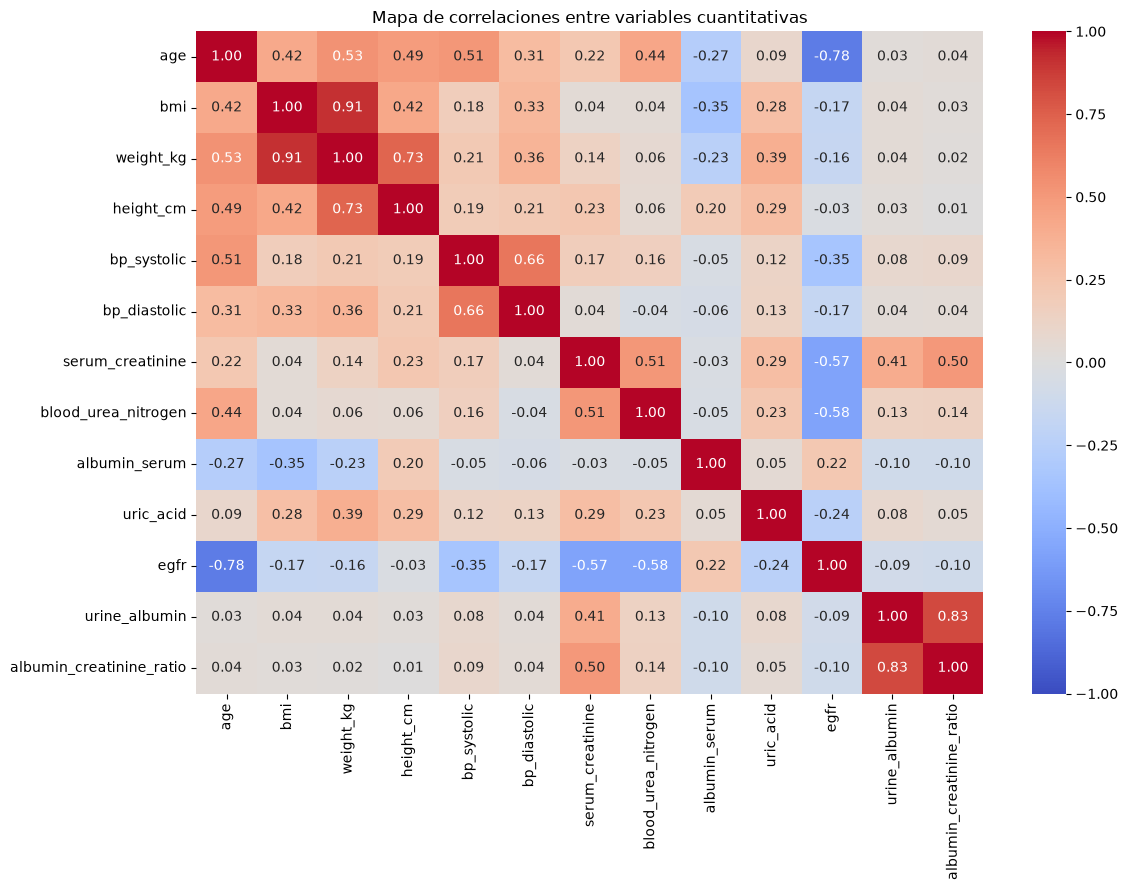

In [18]:

variables_correlacion = [
    "age",
    "bmi",
    "weight_kg",
    "height_cm",
    "bp_systolic",
    "bp_diastolic",
    "serum_creatinine",
    "blood_urea_nitrogen",
    "albumin_serum",
    "uric_acid",
    "egfr",
    "urine_albumin",
    "albumin_creatinine_ratio"
]

matriz_correlacion = df[variables_correlacion].corr(
    method="pearson"
)

plt.figure(figsize=(12, 9))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)
plt.title("Mapa de correlaciones entre variables cuantitativas")
plt.tight_layout()
plt.show()


Correlaciones positivas: las variables tienden a aumentar juntas.



Correlaciones negativas: cuando una aumenta, la otra tiende a disminuir.



Correlaciones cercanas a cero: no hay una relación lineal clara.